<a href="https://colab.research.google.com/github/santhwana27/Machine-Learning-Lab-Programs/blob/main/LINEAR_REGRESSION_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving DatasetLR.csv to DatasetLR (2).csv

TASK 1: LOAD AND INSPECT THE DATASET

First 10 Records:
 Study_Hours  Sleep_Hours  Attendance  Previous_Score  Assignments_Completed  Exam_Score
         1.5          5.7          93              88                     92        60.9
         6.5          6.6          72              69                     79        82.1
         4.1          7.9          92              50                     74        71.4
         6.1          6.8          98              90                     75        84.9
         7.8          7.3          88              52                     99        89.0
         4.8          7.7          79              66                     64        72.0
         4.5          8.0          90              72                     96        72.4
         1.5          7.8          91              86                     94        61.4
         2.9          5.5          90              83                     69        64.6
         4.

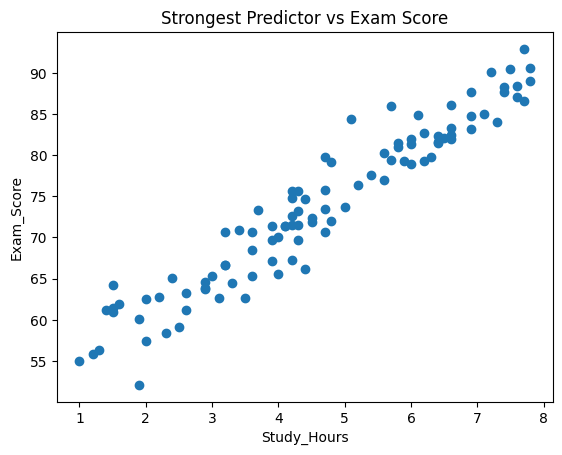


TASK 3: MULTIPLE LINEAR REGRESSION

Training samples: 80
Testing samples: 20
Model trained successfully.

TASK 4: REGRESSION EQUATION

Intercept: 16.1742

Coefficients:
Study_Hours               : 5.0701
Sleep_Hours               : 1.3790
Attendance                : 0.0824
Previous_Score            : 0.1516
Assignments_Completed     : 0.0854

Final Regression Equation:
Exam_Score = 16.1742 + (5.0701 × Study_Hours) + (1.3790 × Sleep_Hours) + (0.0824 × Attendance) + (0.1516 × Previous_Score) + (0.0854 × Assignments_Completed)

TASK 5: MODEL EVALUATION

     Metric  Value
        MAE 0.8311
        MSE 1.0113
       RMSE 1.0057
         R2 0.9884
Adjusted R2 0.9842

TASK 6: EFFECT OF ADDING PREDICTORS

Model Comparison:
                                                                  Model    MAE    MSE   RMSE     R2  Adjusted R2
                                                            Study_Hours 1.9568 5.2311 2.2872 0.9399       0.9365
                                              

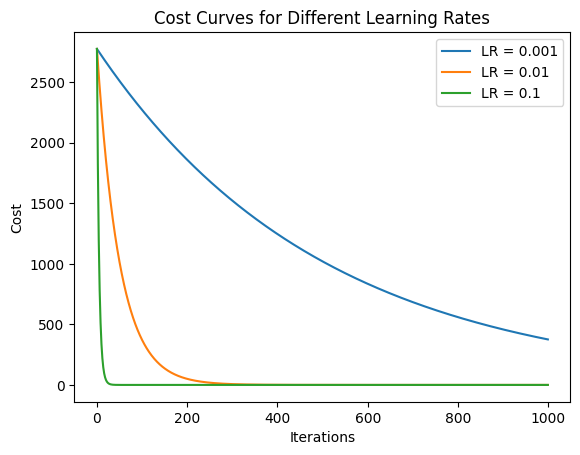


TASK 9: SCIKIT-LEARN VS. GRADIENT DESCENT

Comparison:
     Metric  Scikit-learn  Gradient Descent
        MAE        0.8311            0.8307
        MSE        1.0113            1.0127
       RMSE        1.0057            1.0064
         R2        0.9884            0.9884
Adjusted R2        0.9842            0.9842

TASK 10: PREDICTION FOR A NEW STUDENT

New Student Details:
 Study_Hours  Sleep_Hours  Attendance  Previous_Score  Assignments_Completed
           6            7          90              75                      8

Predicted Exam Score: 75.72


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# TASK 1: LOAD AND INSPECT THE DATASET

uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

features = ['Study_Hours', 'Sleep_Hours', 'Attendance',
            'Previous_Score', 'Assignments_Completed']
target = 'Exam_Score'

print("\n" + "=" * 60)
print("TASK 1: LOAD AND INSPECT THE DATASET")
print("=" * 60)

print("\nFirst 10 Records:")
print(df.head(10).to_string(index=False))

print("\nRows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().to_string())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nIndependent Variables:")
print(features)

print("\nDependent Variable:")
print(target)


# TASK 2: CORRELATION ANALYSIS

corr = df[features + [target]].corr()
strongest = corr[target].drop(target).abs().idxmax()

print("\n" + "=" * 60)
print("TASK 2: CORRELATION ANALYSIS")
print("=" * 60)

print("\nCorrelation Matrix:")
print(corr.round(4).to_string())

print("\nStrongest Predictor:", strongest)

plt.scatter(df[strongest], df[target])
plt.xlabel(strongest)
plt.ylabel("Exam_Score")
plt.title("Strongest Predictor vs Exam Score")
plt.show()


# TASK 3: MULTIPLE LINEAR REGRESSION

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\n" + "=" * 60)
print("TASK 3: MULTIPLE LINEAR REGRESSION")
print("=" * 60)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model trained successfully.")


# TASK 4: REGRESSION EQUATION

print("\n" + "=" * 60)
print("TASK 4: REGRESSION EQUATION")
print("=" * 60)

print("\nIntercept:", round(model.intercept_, 4))

print("\nCoefficients:")

for f, c in zip(features, model.coef_):
    print(f"{f:25s} : {c:.4f}")

print("\nFinal Regression Equation:")
print(
    f"Exam_Score = {model.intercept_:.4f} "
    f"+ ({model.coef_[0]:.4f} × Study_Hours) "
    f"+ ({model.coef_[1]:.4f} × Sleep_Hours) "
    f"+ ({model.coef_[2]:.4f} × Attendance) "
    f"+ ({model.coef_[3]:.4f} × Previous_Score) "
    f"+ ({model.coef_[4]:.4f} × Assignments_Completed)"
)


# TASK 5: MODEL EVALUATION

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

n = len(y_test)
p = len(features)

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("\n" + "=" * 60)
print("TASK 5: MODEL EVALUATION")
print("=" * 60)

evaluation = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2", "Adjusted R2"],
    "Value": [mae, mse, rmse, r2, adjusted_r2]
})

print("\n" + evaluation.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


# TASK 6: EFFECT OF ADDING PREDICTORS

model_features = [
    ['Study_Hours'],
    ['Study_Hours', 'Sleep_Hours'],
    features
]

results = []

for f in model_features:

    m = LinearRegression()
    m.fit(X_train[f], y_train)

    pred = m.predict(X_test[f])

    mae1 = mean_absolute_error(y_test, pred)
    mse1 = mean_squared_error(y_test, pred)
    rmse1 = np.sqrt(mse1)
    r21 = r2_score(y_test, pred)

    p1 = len(f)
    adj1 = 1 - (1 - r21) * (n - 1) / (n - p1 - 1)

    results.append([
        "+".join(f),
        mae1,
        mse1,
        rmse1,
        r21,
        adj1
    ])

comparison = pd.DataFrame(
    results,
    columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2', 'Adjusted R2']
)

print("\n" + "=" * 60)
print("TASK 6: EFFECT OF ADDING PREDICTORS")
print("=" * 60)

print("\nModel Comparison:")
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


# TASK 7: MULTIPLE LINEAR REGRESSION USING GRADIENT DESCENT

scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train_g = np.c_[np.ones(len(X_train_s)), X_train_s]
X_test_g = np.c_[np.ones(len(X_test_s)), X_test_s]

weights = np.zeros(X_train_g.shape[1])

learning_rate = 0.01
epochs = 1000

costs = []

for i in range(epochs):

    prediction = X_train_g @ weights
    error = prediction - y_train.values

    cost = np.mean(error ** 2) / 2
    costs.append(cost)

    gradient = (X_train_g.T @ error) / len(X_train_g)

    weights = weights - learning_rate * gradient

gd_pred = X_test_g @ weights

gd_mae = mean_absolute_error(y_test, gd_pred)
gd_mse = mean_squared_error(y_test, gd_pred)
gd_rmse = np.sqrt(gd_mse)
gd_r2 = r2_score(y_test, gd_pred)

gd_adj_r2 = 1 - (1 - gd_r2) * (n - 1) / (n - p - 1)

print("\n" + "=" * 60)
print("TASK 7: MULTIPLE LINEAR REGRESSION USING GRADIENT DESCENT")
print("=" * 60)

print("\nFinal Weights:")
for f, w in zip(features, weights[1:]):
    print(f"{f:25s} : {w:.4f}")

print("\nBias:", round(weights[0], 4))

gd_evaluation = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2", "Adjusted R2"],
    "Value": [gd_mae, gd_mse, gd_rmse, gd_r2, gd_adj_r2]
})

print("\nGradient Descent Evaluation:")
print(gd_evaluation.to_string(index=False,
                              float_format=lambda x: f"{x:.4f}"))


# TASK 8: LEARNING RATE EXPERIMENT

learning_rates = [0.001, 0.01, 0.1]

lr_results = {}

plt.figure()

for lr in learning_rates:

    w = np.zeros(X_train_g.shape[1])
    cost_list = []

    for i in range(1000):

        prediction = X_train_g @ w
        error = prediction - y_train.values

        cost = np.mean(error ** 2) / 2
        cost_list.append(cost)

        gradient = (X_train_g.T @ error) / len(X_train_g)

        w = w - lr * gradient

    lr_results[lr] = cost_list[-1]

    plt.plot(cost_list, label=f"LR = {lr}")

print("\n" + "=" * 60)
print("TASK 8: LEARNING RATE EXPERIMENT")
print("=" * 60)

lr_table = pd.DataFrame({
    "Learning Rate": learning_rates,
    "Final Cost": [lr_results[lr] for lr in learning_rates]
})

print("\nLearning Rate Comparison:")
print(lr_table.to_string(index=False,
                         float_format=lambda x: f"{x:.4f}"))

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Curves for Different Learning Rates")
plt.legend()
plt.show()


# TASK 9: SCIKIT-LEARN VS. GRADIENT DESCENT

comparison2 = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2', 'Adjusted R2'],
    'Scikit-learn': [
        mae, mse, rmse, r2, adjusted_r2
    ],
    'Gradient Descent': [
        gd_mae, gd_mse, gd_rmse, gd_r2, gd_adj_r2
    ]
})

print("\n" + "=" * 60)
print("TASK 9: SCIKIT-LEARN VS. GRADIENT DESCENT")
print("=" * 60)

print("\nComparison:")
print(comparison2.to_string(index=False,
                            float_format=lambda x: f"{x:.4f}"))


# TASK 10: PREDICTION FOR A NEW STUDENT

new_student = pd.DataFrame({
    'Study_Hours': [6],
    'Sleep_Hours': [7],
    'Attendance': [90],
    'Previous_Score': [75],
    'Assignments_Completed': [8]
})

new_prediction = model.predict(new_student)

print("\n" + "=" * 60)
print("TASK 10: PREDICTION FOR A NEW STUDENT")
print("=" * 60)

print("\nNew Student Details:")
print(new_student.to_string(index=False))

print("\nPredicted Exam Score: {:.2f}".format(new_prediction[0]))